In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("file_azka.csv", dtype= {"no_hp_pelanggan":str})
df.head()

,id_transaksi,id_nota,tanggal_transaksi,tanggal,bulan,hari,jam,nama_kasir,nama_pelanggan,no_hp_pelanggan,...,total_masuk,metode_pembayaran,pembayaran_pertama,status_pengambilan,tanggal_estimasi,pernah_terlambat,terakhir_diperbarui,status_cucian_terakhir,tahap_terakhir,waktu_status_terakhir
0,1,AZK260525DA1C,2026-05-25 07:24:29,2026-05-25,2026-05,Monday,7,Kasir 1,Aisyah Utami,082370540749,...,60000.0,"tunai,transfer",2026-05-25 07:28:36,sudah_diambil,2026-05-30,0,2026-05-30 14:23:02,selesai,NaN,2026-05-30 07:15:44
1,2,AZK2605258635,2026-05-25 07:26:01,2026-05-25,2026-05,Monday,7,Kasir 1,Hesti Alimuddin,085740651974,...,48000.0,tunai,2026-05-25 07:34:58,sudah_diambil,2026-05-28,1,2026-06-06 13:50:27,selesai,NaN,2026-05-27 07:24:45
2,3,AZK2605254A5D,2026-05-25 08:44:54,2026-05-25,2026-05,Monday,8,Kasir 1,Ika Oktaviani,08314838073,...,25000.0,tunai,2026-05-25 08:50:13,sudah_diambil,2026-05-29,0,2026-05-29 09:03:26,selesai,NaN,2026-05-28 07:28:53
3,4,AZK260525B916,2026-05-25 08:54:57,2026-05-25,2026-05,Monday,8,Kasir 1,Salsa Darwis,08956326203,...,80000.0,"tunai,transfer",2026-05-25 09:03:12,sudah_diambil,2026-05-30,1,2026-05-31 10:01:37,selesai,NaN,2026-05-29 08:30:36
4,5,AZK2605255913,2026-05-25 09:10:09,2026-05-25,2026-05,Monday,9,Kasir 1,Dimas Handayani,085385788784,...,106000.0,tunai,2026-05-25 09:17:04,sudah_diambil,2026-05-29,1,2026-06-01 14:13:04,selesai,NaN,2026-05-28 09:00:54


In [4]:
# kita cek data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6236 entries, 0 to 6235
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_transaksi            6236 non-null   int64  
 1   id_nota                 6236 non-null   str    
 2   tanggal_transaksi       6236 non-null   str    
 3   tanggal                 6236 non-null   str    
 4   bulan                   6236 non-null   str    
 5   hari                    6236 non-null   str    
 6   jam                     6236 non-null   int64  
 7   nama_kasir              6236 non-null   str    
 8   nama_pelanggan          6236 non-null   str    
 9   no_hp_pelanggan         6236 non-null   str    
 10  nama_kategori           6236 non-null   str    
 11  nama_item               6236 non-null   str    
 12  tipe_proses             6236 non-null   str    
 13  estimasi_hari           6236 non-null   int64  
 14  qty                     6236 non-null   float64
 15

In [6]:
kosong = df.isna().sum()
kosong[kosong>0]

keterangan_item       5874
jumlah_pembayaran       73
total_masuk             73
metode_pembayaran       73
pembayaran_pertama      73
tahap_terakhir        6121
dtype: int64

In [8]:
buang_variabel = ["id_transaksi", "total_masuk", "tahap_terakhir", "keterangan_item", "nama_kasir", "tanggal", "bulan", "hari", "jam", "sisa_tagihan"]
df = df.drop(columns= buang_variabel)
df.shape

(6236, 24)

In [13]:
for kol in ["tanggal_transaksi", "tanggal_estimasi", "pembayaran_pertama", "terakhir_diperbarui", "waktu_status_terakhir"]:
    df[kol] = pd.to_datetime(df[kol])

df["pernah_terlambat"] = df["pernah_terlambat"].astype(bool)

In [14]:
df["jumlah_pembayaran"] = df["jumlah_pembayaran"].fillna(0)
df["metode_pembayaran"] = df["metode_pembayaran"].fillna("belum ada pembayaran")
df.isna().sum().sum()

np.int64(73)

In [15]:
print("Baris duplikat:", df.duplicated().sum())

Baris duplikat: 0


In [16]:
# Total nota harus sama dengan jumlah subtotal item-itemnya
cek = df.groupby("id_nota").agg(total_nota=("total_nota", "first"), total_item=("subtotal", "sum"))
print("Nota dengan total tidak cocok:", ((cek.total_nota - cek.total_item).abs() > 1).sum())

print("qty <= 0:", (df["qty"] <= 0).sum())
print("subtotal < 0:", (df["subtotal"] < 0).sum())

Nota dengan total tidak cocok: 0
qty <= 0: 0
subtotal < 0: 0


In [17]:
peta_hari = {"Monday": "Senin", "Tuesday": "Selasa", "Wednesday": "Rabu",
             "Thursday": "Kamis", "Friday": "Jumat", "Saturday": "Sabtu", "Sunday": "Minggu"}
urutan_hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

df["tanggal"] = df["tanggal_transaksi"].dt.normalize()
df["bulan"] = df["tanggal_transaksi"].dt.to_period("M").astype(str)
df["hari"] = df["tanggal_transaksi"].dt.day_name().map(peta_hari)
df["jam"] = df["tanggal_transaksi"].dt.hour
df["sisa_tagihan"] = df["total_nota"] - df["total_dibayar"]

In [18]:
df_item = df.copy()   

kolom_nota = ["id_nota", "tanggal_transaksi", "bulan", "hari", "jam", "nama_pelanggan",
              "no_hp_pelanggan", "total_nota", "status_bayar", "total_dibayar", "sisa_tagihan",
              "metode_pembayaran", "status_pengambilan", "pernah_terlambat"]

df_nota = df.drop_duplicates(subset="id_nota")[kolom_nota]   # 1 baris = 1 nota

print("Jumlah item:", len(df_item), "| Jumlah nota:", len(df_nota))
print(f"Total omzet: Rp{df_nota['total_nota'].sum():,.0f}")

Jumlah item: 6236 | Jumlah nota: 5200
Total omzet: Rp254,079,500


In [19]:
df_pelanggan = (df_nota.groupby("no_hp_pelanggan")
                .agg(nama=("nama_pelanggan", "first"),
                     jumlah_transaksi=("id_nota", "count"),
                     total_belanja=("total_nota", "sum"))
                .reset_index())

df_pelanggan["tipe"] = np.where(df_pelanggan["jumlah_transaksi"] > 1, "Repeat", "Sekali beli")
df_pelanggan.sort_values("total_belanja", ascending=False).head()

,no_hp_pelanggan,nama,jumlah_transaksi,total_belanja,tipe
31,081165376603,Dimas Baharuddin,184,8251500.0,Repeat
75,08127611442,Muhammad Rahman,106,5606500.0,Repeat
47,08120425098,Rizky Nur,87,4005500.0,Repeat
614,087830258499,Maya Oktaviani,77,3810500.0,Repeat
366,085195452084,Muhammad Burhan,64,3321500.0,Repeat


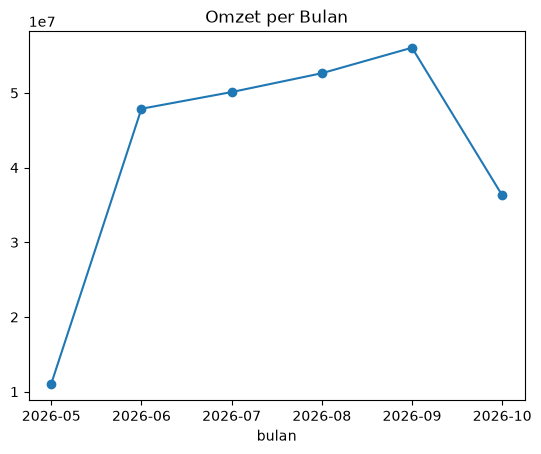

In [20]:
df_nota.groupby("bulan")["total_nota"].sum().plot(kind="line", marker="o", title="Omzet per Bulan")
plt.show()

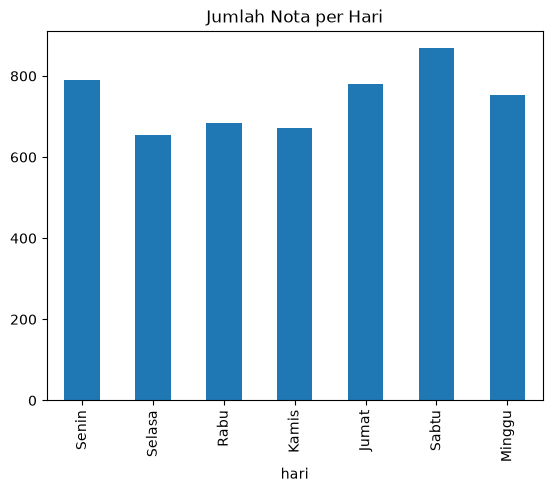

In [21]:
df_nota["hari"].value_counts().reindex(urutan_hari).plot(kind="bar", title="Jumlah Nota per Hari")
plt.show()

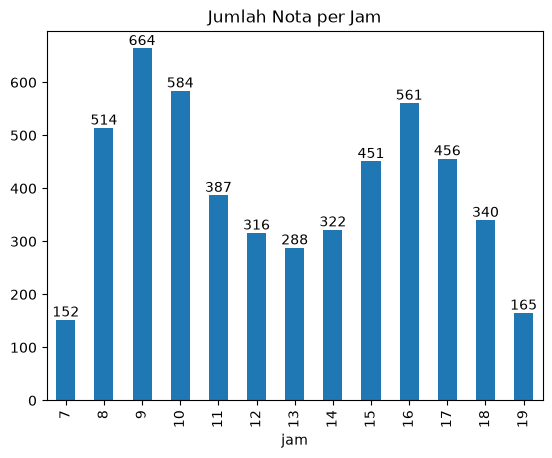

In [38]:
ax = df_nota["jam"].value_counts().sort_index().plot(kind="bar", title="Jumlah Nota per Jam")
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.show()

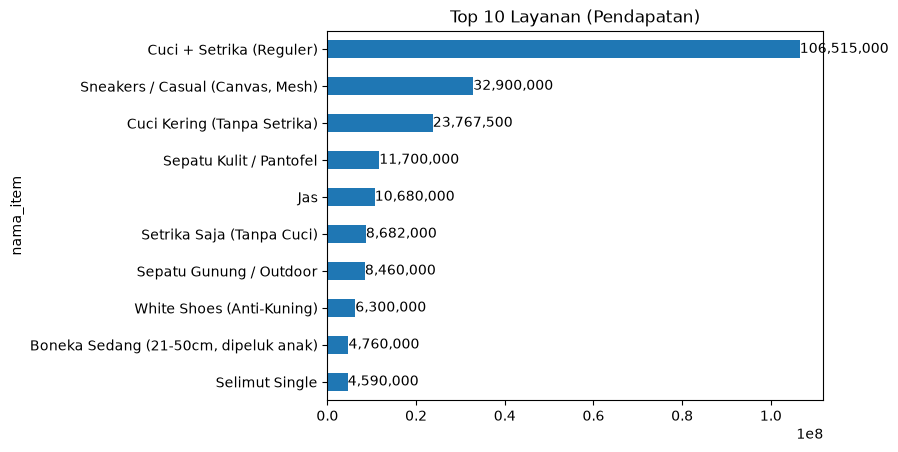

In [37]:
top = df_item.groupby("nama_item")["subtotal"].sum().sort_values(ascending=False).head(10)   # UBAH: angka 10
ax = top.sort_values().plot(kind="barh", title="Top 10 Layanan (Pendapatan)")
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.show()

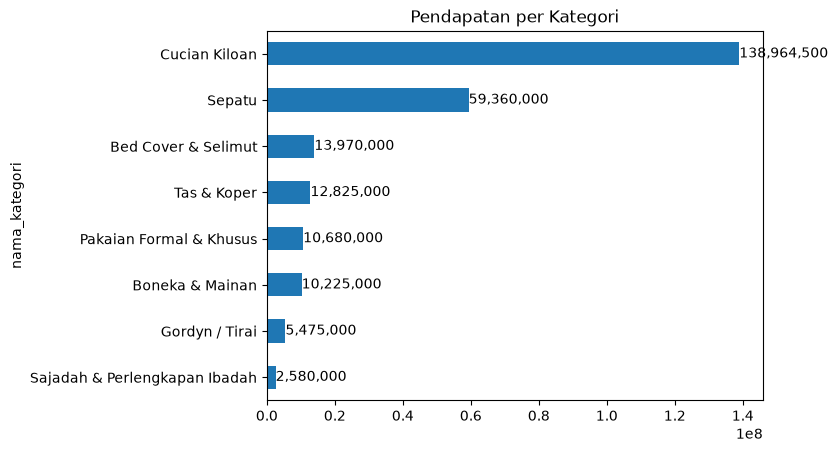

In [35]:
ax = df_item.groupby("nama_kategori")["subtotal"].sum().sort_values().plot(kind="barh", title="Pendapatan per Kategori")
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.show()

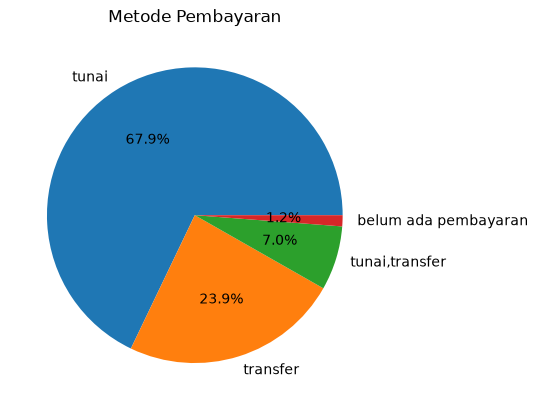

In [26]:
df_nota["metode_pembayaran"].value_counts().plot(kind="pie", autopct="%1.1f%%", title="Metode Pembayaran")
plt.show()

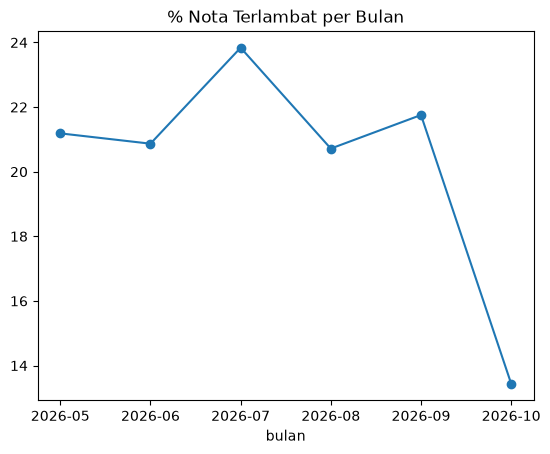

In [34]:
(df_nota.groupby("bulan")["pernah_terlambat"].mean() * 100).plot(kind="line", marker="o", title="% Nota Terlambat per Bulan")
plt.show()

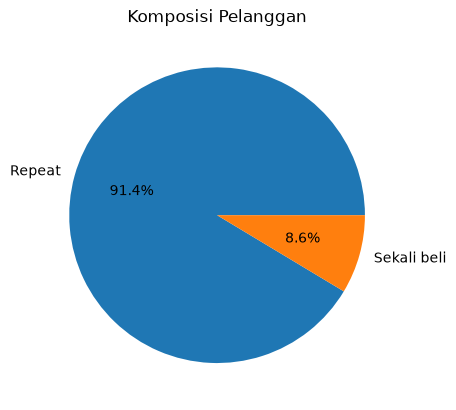

In [32]:
df_pelanggan["tipe"].value_counts().plot(kind="pie", autopct="%1.1f%%", title="Komposisi Pelanggan")
plt.show()

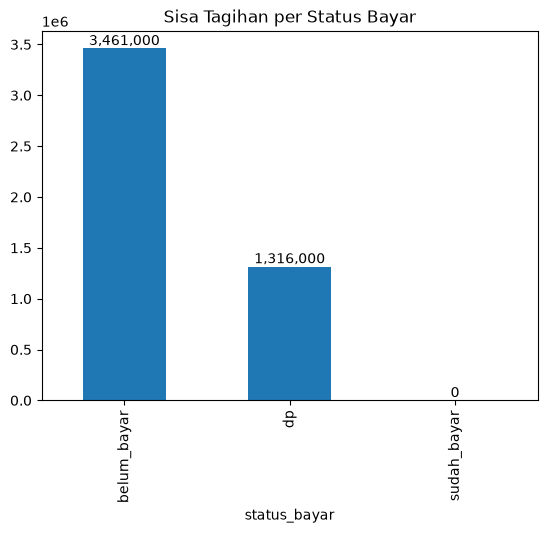

In [30]:
ax= df_nota.groupby("status_bayar")["sisa_tagihan"].sum().plot(kind="bar", title="Sisa Tagihan per Status Bayar")
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.show()